In [ ]:
!pip install -q catboost joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.7 MB/s eta 0:00:00


In [ ]:
import os
import re
import zipfile
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")

In [ ]:
print("CATBOOST RAINFALL FORECASTING PROJECT")

df = pd.read_csv('/content/DOC-20260923-WA0011.csv')

print("✓ Dataset loaded successfully")

print(f"Rows    : {len(df)}")
print(f"Columns : {len(df.columns)}")

CATBOOST RAINFALL FORECASTING PROJECT
✓ Dataset loaded successfully
Rows    : 1441
Columns : 21


In [ ]:
# Clean column names

df.columns = (df.columns.astype(str).str.replace("\n", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip())
# Required columns

required = ["State","Date","Daily Actual"]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


# Clean values

df["State"] = (df["State"].astype(str).str.upper().str.strip())

df["Date"] = pd.to_datetime(df["Date"],errors="coerce")

df["Daily Actual"] = pd.to_numeric(df["Daily Actual"],errors="coerce")


# Remove invalid rows

df = df.dropna(subset=["State","Date","Daily Actual"]).copy()

print("✓ Dataset cleaned successfully")
print(f"Usable rows: {len(df)}")

✓ Dataset cleaned successfully
Usable rows: 1441


In [ ]:
input_states = [
    "UTTARAKHAND",
    "UTTAR PRADESH",
    "HARYANA",
    "PUNJAB",
    "HIMACHAL PRADESH",
    "MADHYA PRADESH",
    "RAJASTHAN"
]

target_state = "DELHI (UT)"

required_states = (input_states +[target_state])

# Check whether all required states exist

missing_states = [state for state in required_states if state not in df["State"].unique()]

if missing_states:
  raise ValueError("Missing states:\n" + "\n".join(missing_states))

print("✓ All required states are available")

print("\nInput states:")
for state in input_states:
    print("•", state)

print("\nTarget:")
print("•", target_state)

✓ All required states are available

Input states:
• UTTARAKHAND
• UTTAR PRADESH
• HARYANA
• PUNJAB
• HIMACHAL PRADESH
• MADHYA PRADESH
• RAJASTHAN

Target:
• DELHI (UT)


In [ ]:
print("DATASET SUMMARY")

print(f"\nRows          : {len(df)}")
print(f"Columns       : {len(df.columns)}")
print(f"Unique states : {df['State'].nunique()}")
print(f"Unique dates  : {df['Date'].nunique()}")

print(
    f"Date range   : "
    f"{df['Date'].min().date()} → "
    f"{df['Date'].max().date()}"
)

print("\nDataset preview:")

display(df.head())

DATASET SUMMARY

Rows          : 1441
Columns       : 21
Unique states : 41
Unique dates  : 37
Date range   : 2022-05-31 → 2026-09-23

Dataset preview:


,State,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly Actual,Weekly Normal,Weekly Departure Per,...,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative Category,Monthly Date,Monthly Acutual,Monthly Normal,Monthly Departure Per,Monthly Category
0,ANDAMAN & NICOBAR (UT),2026-08-19,4.1,12.9,-68%,LD,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 19-08-2026,1062.7,1038.7,2%,N\n,From 01-08-2026 To 19-08-2026\n,238.1,234.1,2%,N\n
1,ANDAMAN & NICOBAR (UT),2026-08-20,23.5,11.9,97%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 20-08-2026,1086.2,1050.6,3%,N\n,From 01-08-2026 To 20-08-2026\n,261.6,246.0,6%,N\n
2,ANDAMAN & NICOBAR (UT),2026-08-21,30.7,12.4,148%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 21-08-2026,1116.9,1063.0,5%,N\n,From 01-08-2026 To 21-08-2026\n,292.3,258.4,13%,N\n
3,ANDAMAN & NICOBAR (UT),2026-08-22,46.8,11.6,303%,LE,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 22-08-2026,1163.7,1074.6,8%,N\n,From 01-08-2026 To 22-08-2026\n,339.1,270.0,26%,E\n
4,ANDAMAN & NICOBAR (UT),2026-08-23,9.8,15.1,-35%,D,13-08-2026 To 19-08-2026,41.5,77.3,-46%,...,01-06-2026 To 23-08-2026,1173.5,1089.7,8%,N\n,From 01-08-2026 To 23-08-2026\n,348.9,285.1,22%,E\n


In [ ]:
data = df[
    df["State"].isin(required_states)].copy()

print("✓ Required states selected")

print(
    f"Selected rows: {len(data)}"
)

✓ Required states selected
Selected rows: 288


In [ ]:
state_daily = (data.groupby(["Date", "State"],as_index=False)["Daily Actual"].mean())

wide = (state_daily.pivot(index="Date", columns="State", values="Daily Actual").reset_index())

wide.columns.name = None

wide = (wide.sort_values("Date").reset_index(drop=True))

print("✓ State-wise daily dataset created")

display(wide.head())

✓ State-wise daily dataset created


,Date,DELHI (UT),HARYANA,HIMACHAL PRADESH,MADHYA PRADESH,PUNJAB,RAJASTHAN,UTTAR PRADESH,UTTARAKHAND
0,2026-08-19,0.7,3.9,24.7,10.9,12.3,0.0,10.2,15.2
1,2026-08-20,7.8,1.9,4.3,16.8,2.0,0.0,11.8,12.4
2,2026-08-21,0.8,2.0,0.5,10.9,7.4,0.4,4.5,10.7
3,2026-08-22,6.1,3.3,7.8,9.8,2.6,0.1,9.2,6.1
4,2026-08-23,2.9,3.5,9.5,10.2,1.0,0.5,7.3,8.1


In [ ]:
features = []

for state in input_states:
    feature = (state.lower().replace(" ", "_")+ "_previous_day")
    wide[feature] = (wide[state].shift(1))
    features.append(feature)


# Delhi rainfall becomes target

wide["Delhi_Rainfall"] = (wide[target_state])
print("✓ Previous-day features created")

print("\nFeatures used by CatBoost:")

for feature in features:
    print("•", feature)

✓ Previous-day features created

Features used by CatBoost:
• uttarakhand_previous_day
• uttar_pradesh_previous_day
• haryana_previous_day
• punjab_previous_day
• himachal_pradesh_previous_day
• madhya_pradesh_previous_day
• rajasthan_previous_day


In [ ]:
model_data = wide[["Date"] +features +["Delhi_Rainfall"]].dropna().reset_index(drop=True)

print("MODEL DATASET")

print(
    f"\nUsable samples: {len(model_data)}"
)

display(model_data.head())

MODEL DATASET

Usable samples: 35


,Date,uttarakhand_previous_day,uttar_pradesh_previous_day,haryana_previous_day,punjab_previous_day,himachal_pradesh_previous_day,madhya_pradesh_previous_day,rajasthan_previous_day,Delhi_Rainfall
0,2026-08-20,15.2,10.2,3.9,12.3,24.7,10.9,0.0,7.8
1,2026-08-21,12.4,11.8,1.9,2.0,4.3,16.8,0.0,0.8
2,2026-08-22,10.7,4.5,2.0,7.4,0.5,10.9,0.4,6.1
3,2026-08-23,6.1,9.2,3.3,2.6,7.8,9.8,0.1,2.9
4,2026-08-24,8.1,7.3,3.5,1.0,9.5,10.2,0.5,4.9


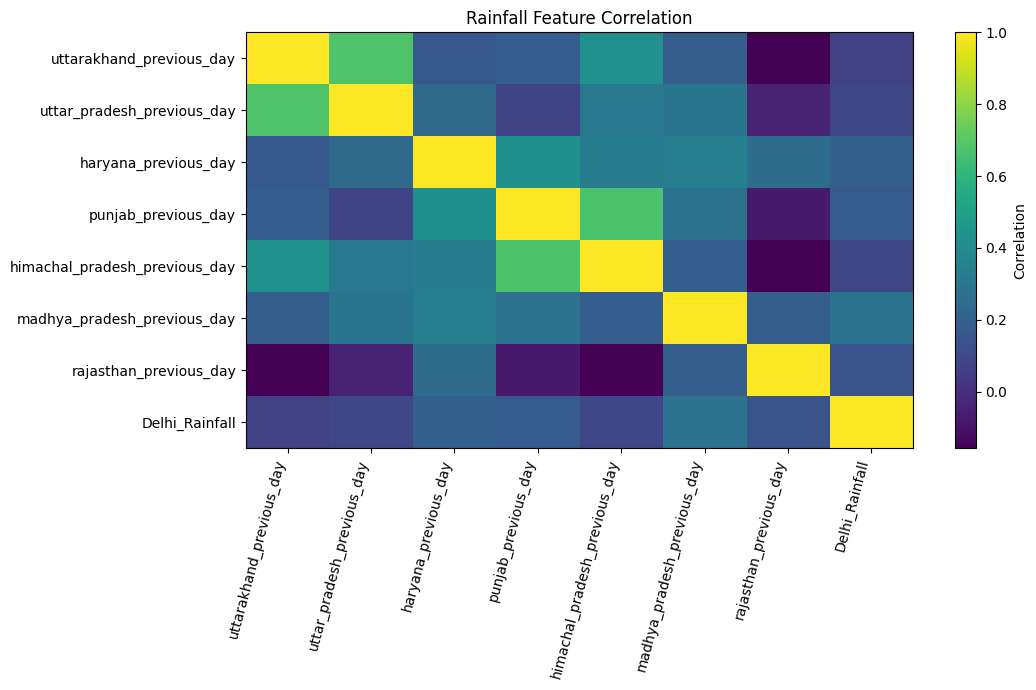

In [ ]:
plt.figure(
    figsize=(11, 7)
)

corr = model_data[features +["Delhi_Rainfall"]].corr()

plt.imshow(
    corr,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=75,
    ha="right"
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title(
    "Rainfall Feature Correlation"
)

plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
X = model_data[features]

y = model_data["Delhi_Rainfall"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (35, 7)
y shape: (35,)


In [ ]:
n = len(model_data)

train_end = int(n * 0.70)

val_end = int(n * 0.85)

X_train = X.iloc[:train_end]

y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]

y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]

y_test = y.iloc[val_end:]

print("=" * 65)
print("DATA SPLIT")
print("=" * 65)

print(
    f"\nTraining samples   : {len(X_train)}"
)

print(
    f"Validation samples : {len(X_val)}"
)

print(
    f"Testing samples    : {len(X_test)}"
)


print(
    f"\nTraining period   : "
    f"{model_data['Date'].iloc[0].date()} → "
    f"{model_data['Date'].iloc[train_end-1].date()}"
)

print(
    f"Validation period : "
    f"{model_data['Date'].iloc[train_end].date()} → "
    f"{model_data['Date'].iloc[val_end-1].date()}"
)

print(
    f"Testing period    : "
    f"{model_data['Date'].iloc[val_end].date()} → "
    f"{model_data['Date'].iloc[-1].date()}"
)

DATA SPLIT

Training samples   : 24
Validation samples : 5
Testing samples    : 6

Training period   : 2026-08-20 → 2026-09-12
Validation period : 2026-09-13 → 2026-09-17
Testing period    : 2026-09-18 → 2026-09-23


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)
print("✓ Features scaled successfully")

✓ Features scaled successfully


In [ ]:
print("TRAINING CATBOOST")

model = CatBoostRegressor(
  iterations=500,
  depth=6,
  learning_rate=0.03,
  loss_function="RMSE",
  random_seed=42,
  verbose=False
)

model.fit(
  X_train_scaled,
  y_train,
  eval_set=(
        X_val_scaled,
        y_val
    ),

  use_best_model=True,
  verbose=False
)


print("\n✓ CatBoost training completed")

print(
    "Best iteration:",
    model.get_best_iteration()
)

TRAINING CATBOOST

✓ CatBoost training completed
Best iteration: 2


In [ ]:
train_pred = model.predict(X_train_scaled)

val_pred = model.predict(
    X_val_scaled
)

test_pred = model.predict(
    X_test_scaled
)

print("✓ Predictions generated")

✓ Predictions generated


In [ ]:
def calculate_metrics(
    actual,
    predicted
):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mse
    )

    if np.var(actual) == 0:

        r2 = np.nan

    else:

        r2 = r2_score(
            actual,
            predicted
        )

    return mae, mse, rmse, r2


train_metrics = calculate_metrics(
    y_train,
    train_pred
)

val_metrics = calculate_metrics(
    y_val,
    val_pred
)

test_metrics = calculate_metrics(
    y_test,
    test_pred
)


print("✓ Metrics calculated")

✓ Metrics calculated


In [ ]:
metrics_df = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Testing"
    ],

    "MAE": [
        train_metrics[0],
        val_metrics[0],
        test_metrics[0]
    ],

    "MSE": [
        train_metrics[1],
        val_metrics[1],
        test_metrics[1]
    ],

    "RMSE": [
        train_metrics[2],
        val_metrics[2],
        test_metrics[2]
    ],

    "R2": [
        train_metrics[3],
        val_metrics[3],
        test_metrics[3]
    ]
})

print("MODEL PERFORMANCE")

display(
    metrics_df.style.format({
        "MAE": "{:.4f}",
        "MSE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
)

MODEL PERFORMANCE


,Dataset,MAE,MSE,RMSE,R2
0,Training,6.4132,116.2628,10.7825,0.0488
1,Validation,5.5222,31.2577,5.5909,-36.6780
2,Testing,5.9902,35.8878,5.9906,nan


In [ ]:
test_dates = (
    model_data["Date"]
    .iloc[val_end:]
    .reset_index(drop=True)
)

prediction_df = pd.DataFrame({
    "Date":
        test_dates,
    "Actual_Rainfall":
        y_test.reset_index(drop=True),
    "Predicted_Rainfall":
        test_pred
})

prediction_df["Error"] = (prediction_df["Actual_Rainfall"]-prediction_df["Predicted_Rainfall"])

print("TEST PREDICTIONS")

display(
    prediction_df.style.format({
        "Actual_Rainfall": "{:.3f}",
        "Predicted_Rainfall": "{:.3f}",
        "Error": "{:.3f}"
    })
)

TEST PREDICTIONS


,Date,Actual_Rainfall,Predicted_Rainfall,Error
0,2026-09-18 00:00:00,0.000,6.129,-6.129
1,2026-09-19 00:00:00,0.000,6.011,-6.011
2,2026-09-20 00:00:00,0.000,6.011,-6.011
3,2026-09-21 00:00:00,0.000,5.939,-5.939
4,2026-09-22 00:00:00,0.000,5.939,-5.939
5,2026-09-23 00:00:00,0.000,5.912,-5.912


In [ ]:
importance_df = pd.DataFrame({
    "Feature":features,
    "Importance":model.feature_importances_}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("FEATURE IMPORTANCE")

display(
    importance_df.style.format({

        "Importance": "{:.2f}"

    })
)

FEATURE IMPORTANCE


,Feature,Importance
0,haryana_previous_day,82.27
1,rajasthan_previous_day,9.43
2,uttarakhand_previous_day,2.49
3,madhya_pradesh_previous_day,2.22
4,himachal_pradesh_previous_day,2.22
5,uttar_pradesh_previous_day,0.75
6,punjab_previous_day,0.62


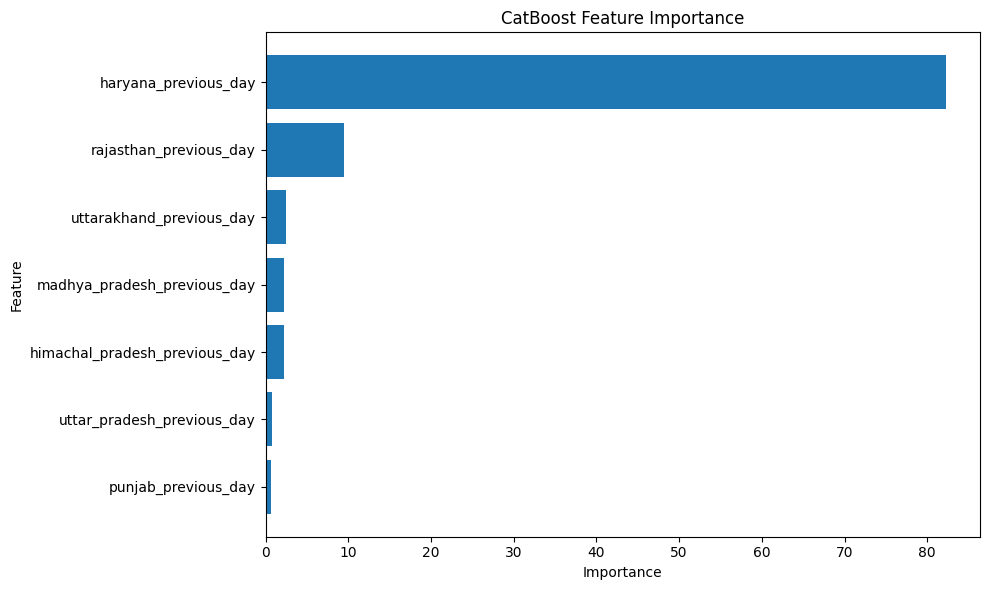

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "CatBoost Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

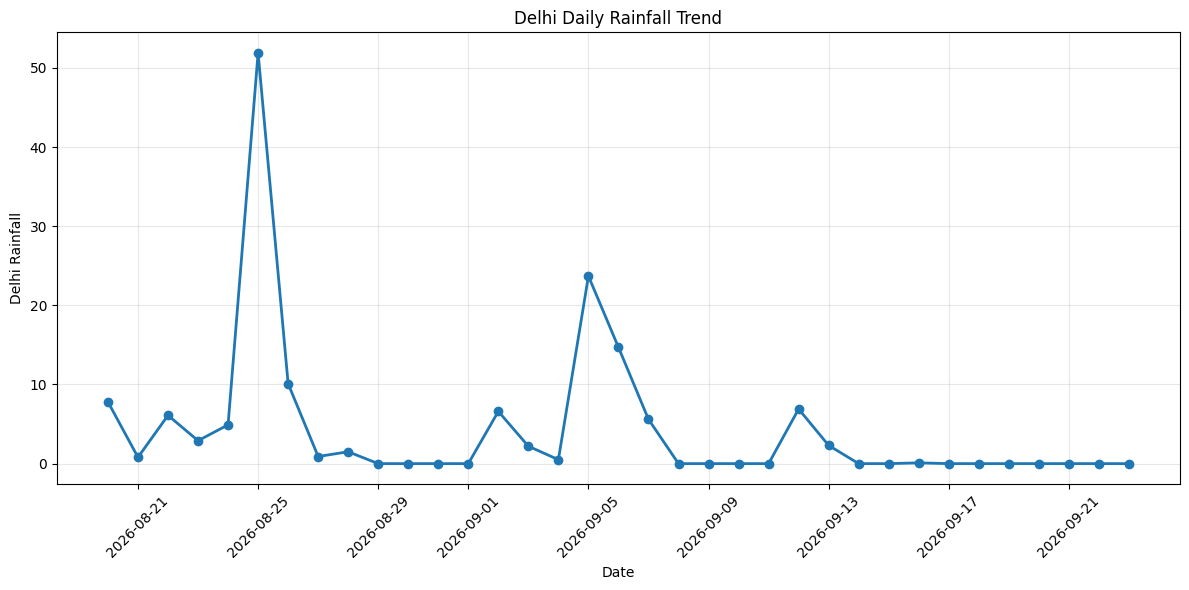

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    model_data["Date"],
    model_data["Delhi_Rainfall"],
    marker="o",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("Delhi Rainfall")
plt.title("Delhi Daily Rainfall Trend")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "delhi_rainfall_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

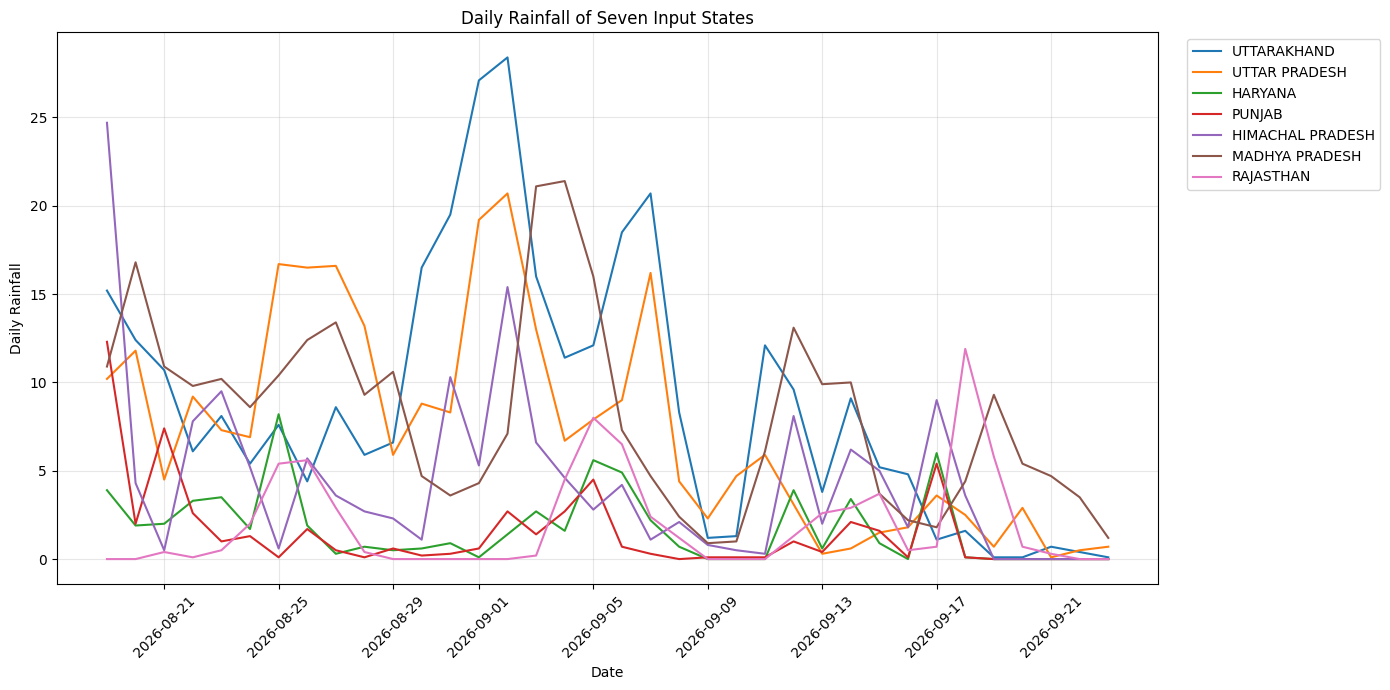

In [ ]:
plt.figure(
    figsize=(14, 7)
)

for state in input_states:
    plt.plot(
        wide["Date"],
        wide[state],
        label=state
    )
plt.xlabel(
    "Date"
)
plt.ylabel(
    "Daily Rainfall"
)
plt.title(
    "Daily Rainfall of Seven Input States"
)
plt.xticks(
    rotation=45
)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(
    alpha=0.3
)
plt.tight_layout()
plt.savefig(
    "input_states_rainfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

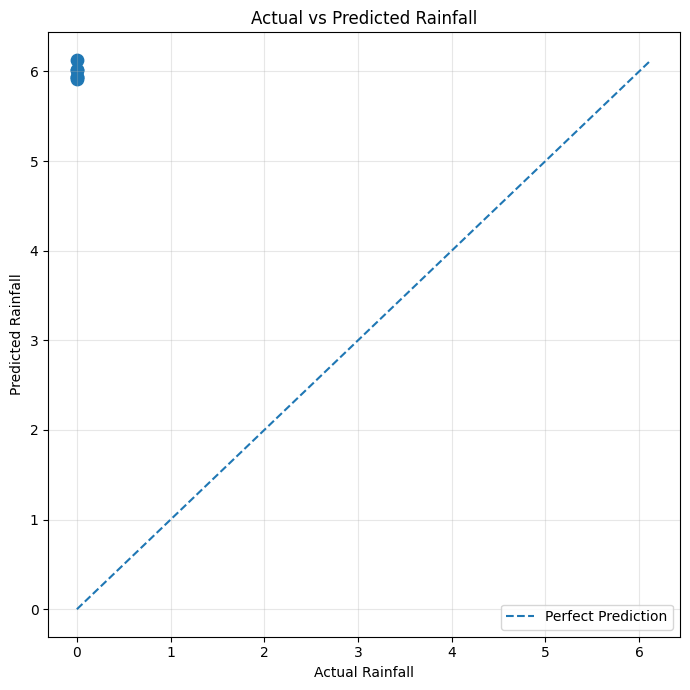

In [ ]:
plt.figure(
    figsize=(7, 7)
)

plt.scatter(

    prediction_df["Actual_Rainfall"],

    prediction_df["Predicted_Rainfall"],

    s=80

)


minimum = min(

    prediction_df["Actual_Rainfall"].min(),

    prediction_df["Predicted_Rainfall"].min()

)


maximum = max(

    prediction_df["Actual_Rainfall"].max(),

    prediction_df["Predicted_Rainfall"].max()

)


plt.plot(

    [minimum, maximum],

    [minimum, maximum],

    linestyle="--",

    label="Perfect Prediction"

)


plt.xlabel(
    "Actual Rainfall"
)

plt.ylabel(
    "Predicted Rainfall"
)

plt.title(
    "Actual vs Predicted Rainfall"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "actual_vs_predicted_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

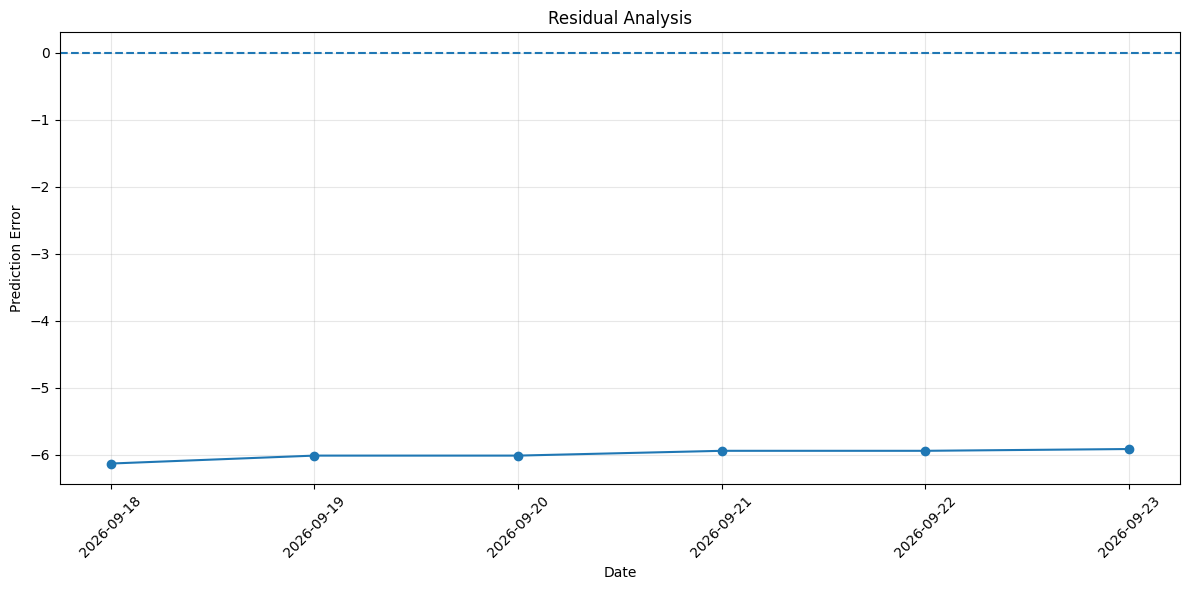

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(

    prediction_df["Date"],

    prediction_df["Error"],

    marker="o"

)

plt.axhline(

    0,

    linestyle="--"

)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Prediction Error"
)

plt.title(
    "Residual Analysis"
)

plt.xticks(
    rotation=45
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("CATBOOST RAINFALL FORECASTING PROJECT COMPLETED")
print(
    f"""
Dataset samples    : {len(model_data)}
Training samples   : {len(X_train)}
Validation samples : {len(X_val)}
Testing samples    : {len(X_test)}

Test MAE  : {test_metrics[0]:.6f}
Test MSE  : {test_metrics[1]:.6f}
Test RMSE : {test_metrics[2]:.6f}
Test R²   : {test_metrics[3]}
"""
)



print(
    "\n✓ All project files are ready."
)

CATBOOST RAINFALL FORECASTING PROJECT COMPLETED

Dataset samples    : 35
Training samples   : 24
Validation samples : 5
Testing samples    : 6

Test MAE  : 5.990210
Test MSE  : 35.887849
Test RMSE : 5.990647
Test R²   : nan


✓ All project files are ready.


# XGBOOST

In [ ]:
print("TRAINING XGBOOST")

model = XGBRegressor(

    n_estimators=500,

    max_depth=6,

    learning_rate=0.03,

    objective="reg:squarederror",

    eval_metric="rmse",

    random_state=42,

    n_jobs=-1
)


model.fit(

    X_train_scaled,

    y_train,

    eval_set=[
        (
            X_val_scaled,
            y_val
        )
    ],

    verbose=False
)


print(
    "\n✓ XGBoost training completed"
)

TRAINING XGBOOST

✓ XGBoost training completed


In [ ]:
importance_df = pd.DataFrame({

    "Feature":
        features,

    "Importance":
        model.feature_importances_

}).sort_values(

    "Importance",

    ascending=False

).reset_index(drop=True)


print("=" * 65)
print("XGBOOST FEATURE IMPORTANCE")
print("=" * 65)

display(
    importance_df.style.format({
        "Importance": "{:.4f}"
    })
)

XGBOOST FEATURE IMPORTANCE


,Feature,Importance
0,uttar_pradesh_previous_day,0.4827
1,rajasthan_previous_day,0.3992
2,punjab_previous_day,0.0479
3,haryana_previous_day,0.0379
4,himachal_pradesh_previous_day,0.0294
5,uttarakhand_previous_day,0.0028
6,madhya_pradesh_previous_day,0.0000


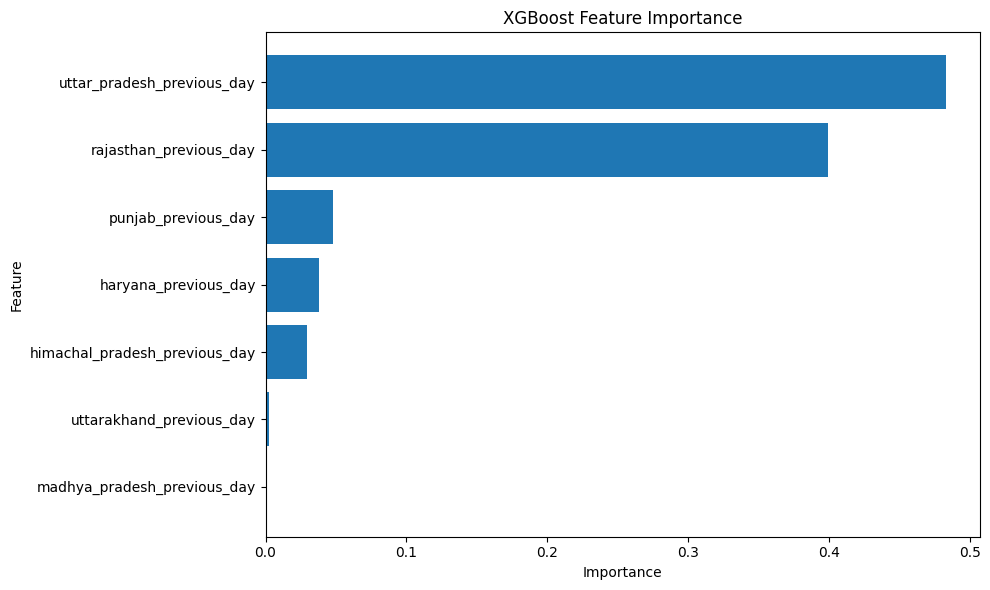

In [ ]:
plt.figure(
    figsize=(10, 6)
)

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel(
    "Importance"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "XGBoost Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "xgboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

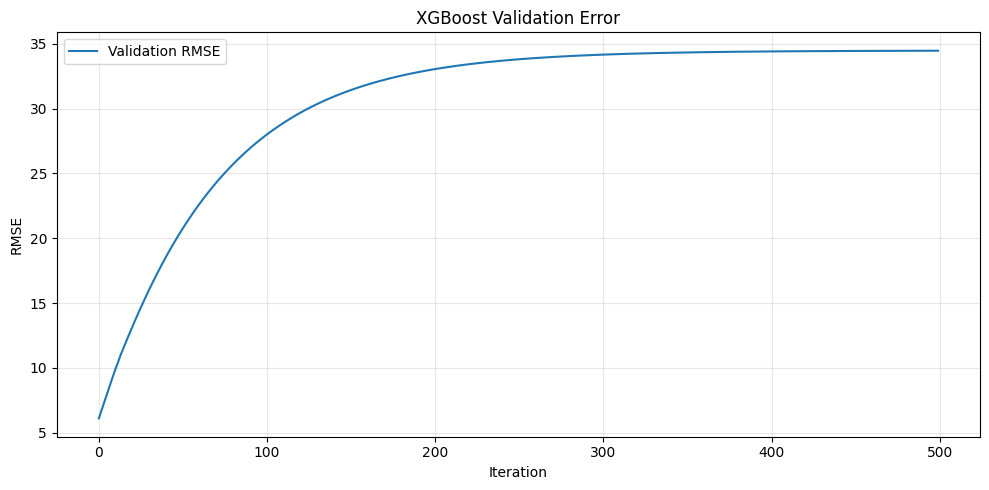

In [ ]:
results = model.evals_result()

if "validation_0" in results:

    plt.figure(
        figsize=(10, 5)
    )

    plt.plot(
        results["validation_0"]["rmse"],
        label="Validation RMSE"
    )

    plt.xlabel(
        "Iteration"
    )

    plt.ylabel(
        "RMSE"
    )

    plt.title(
        "XGBoost Validation Error"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.savefig(
        "xgboost_training_history.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
model.save_model(
    "xgboost_rainfall_model.json"
)

joblib.dump(
    scaler,
    "xgboost_standard_scaler.pkl"
)

metrics_df.to_csv(
    "xgboost_metrics.csv",
    index=False
)

prediction_df.to_csv(
    "xgboost_test_predictions.csv",
    index=False
)

importance_df.to_csv(
    "xgboost_feature_importance.csv",
    index=False
)

model_data.to_csv(
    "xgboost_processed_rainfall_dataset.csv",
    index=False
)

wide.to_csv(
    "xgboost_state_wise_rainfall.csv",
    index=False
)

print("✓ XGBoost model saved")
print("✓ Scaler saved")
print("✓ CSV result files saved")

✓ XGBoost model saved
✓ Scaler saved
✓ CSV result files saved


In [ ]:
print("\n" + "=" * 65)

print(
    "XGBOOST RAINFALL FORECASTING PROJECT COMPLETED"
)

print("=" * 65)

print(
    f"""
Dataset samples    : {len(model_data)}

Training samples   : {len(X_train)}

Validation samples : {len(X_val)}

Testing samples    : {len(X_test)}

Test MAE  : {test_metrics[0]:.6f}

Test MSE  : {test_metrics[1]:.6f}

Test RMSE : {test_metrics[2]:.6f}

Test R²   : {test_metrics[3]}
"""
)

if len(model_data) < 100:

    print("=" * 65)
    print("⚠ DATASET WARNING")
    print("=" * 65)

print(
    "\n✓ All XGBoost project files are ready."
)


XGBOOST RAINFALL FORECASTING PROJECT COMPLETED

Dataset samples    : 35

Training samples   : 24

Validation samples : 5

Testing samples    : 6

Test MAE  : 5.990210

Test MSE  : 35.887849

Test RMSE : 5.990647

Test R²   : nan

⚠ DATASET WARNING

✓ All XGBoost project files are ready.
